Matplotlib is building the font cache; this may take a moment.


1. Gerando dados de transações sintéticas...
Total de transações: 5100
Transações legítimas (Classe 0): 5000
Transações anômalas (Classe 1): 100

2. Treinando o modelo Isolation Forest...



--- Relatório de Classificação ---
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      1500
    Anomalia       0.97      1.00      0.98        30

    accuracy                           1.00      1530
   macro avg       0.98      1.00      0.99      1530
weighted avg       1.00      1.00      1.00      1530



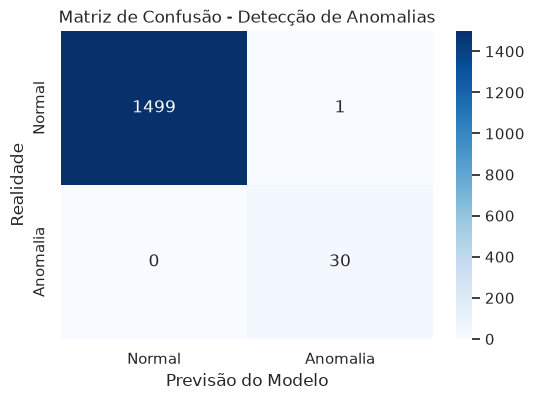

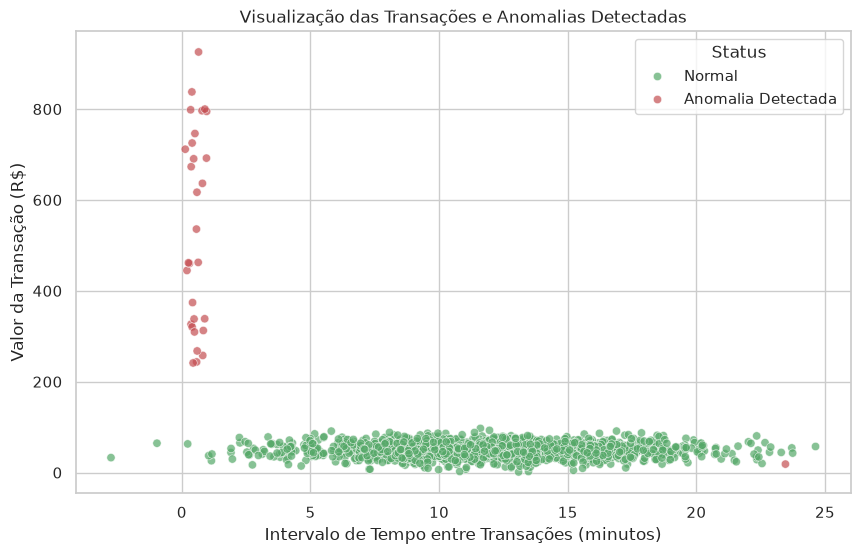

In [1]:
# Detecção de Anomalias em Transações Financeiras usando Isolation Forest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

# Configuração de estilo para os gráficos
sns.set_theme(style="whitegrid")
np.random.seed(42)

# =====================================================================
# 1. Geração de Dados Sintéticos de Transações
# =====================================================================
print("1. Gerando dados de transações sintéticas...")

# Criando transações legítimas (normais)
n_normal = 5000
valor_normal = np.random.normal(loc=50, scale=15, size=n_normal)      # Valores em torno de R$ 50
intervalo_normal = np.random.normal(loc=12, scale=4, size=n_normal)   # Intervalo de tempo médio entre transações

# Criando transações anômalas (fraudes potenciais)
n_anomalo = 100
valor_anomalo = np.random.uniform(low=200, high=1000, size=n_anomalo)  # Valores muito altos
intervalo_anomalo = np.random.uniform(low=0.1, high=1, size=n_anomalo) # Transações muito rápidas/consecutivas

# Unindo os dados em um DataFrame
data_normal = pd.DataFrame({'Valor': valor_normal, 'Intervalo_Tempo': intervalo_normal, 'Classe': 0})
data_anomalo = pd.DataFrame({'Valor': valor_anomalo, 'Intervalo_Tempo': intervalo_anomalo, 'Classe': 1})
df = pd.concat([data_normal, data_anomalo], ignore_index=True)

print(f"Total de transações: {len(df)}")
print(f"Transações legítimas (Classe 0): {len(data_normal)}")
print(f"Transações anômalas (Classe 1): {len(data_anomalo)}\n")

# =====================================================================
# 2. Pré-processamento e Divisão dos Dados
# =====================================================================
X = df[['Valor', 'Intervalo_Tempo']]
y = df['Classe']

# Escalonamento dos atributos para melhorar a performance do modelo
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Divisão em treino e teste (mantendo a proporção de anomalias)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

# =====================================================================
# 3. Treinamento do Modelo (Isolation Forest)
# =====================================================================
print("2. Treinando o modelo Isolation Forest...")

# Definindo a taxa de contaminação aproximada (fração de anomalias esperada)
contamination_rate = len(data_anomalo) / len(df)

model = IsolationForest(contamination=contamination_rate, random_state=42)
model.fit(X_train)

# =====================================================================
# 4. Predição e Avaliação
# =====================================================================
# O Isolation Forest retorna -1 para anomalias e 1 para dados normais.
# Vamos mapear: -1 -> 1 (Anomalia) e 1 -> 0 (Normal)
y_pred_raw = model.predict(X_test)
y_pred = np.where(y_pred_raw == -1, 1, 0)

print("\n--- Relatório de Classificação ---")
print(classification_report(y_test, y_pred, target_names=['Normal', 'Anomalia']))

# Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Anomalia'], yticklabels=['Normal', 'Anomalia'])
plt.ylabel('Realidade')
plt.xlabel('Previsão do Modelo')
plt.title('Matriz de Confusão - Detecção de Anomalias')
plt.show()

# =====================================================================
# 5. Visualização Gráfica dos Resultados
# =====================================================================
# Revertendo o escalonamento para visualização real
X_test_original = scaler.inverse_transform(X_test)
df_test = pd.DataFrame(X_test_original, columns=['Valor', 'Intervalo_Tempo'])
df_test['Previsao'] = np.where(y_pred == 1, 'Anomalia Detectada', 'Normal')

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_test,
    x='Intervalo_Tempo',
    y='Valor',
    hue='Previsao',
    palette={'Normal': 'g', 'Anomalia Detectada': 'r'},
    alpha=0.7
)

plt.title('Visualização das Transações e Anomalias Detectadas')
plt.xlabel('Intervalo de Tempo entre Transações (minutos)')
plt.ylabel('Valor da Transação (R$)')
plt.legend(title='Status')
plt.show()


### 1. Geração de Dados Sintéticos de Transações

Nesta etapa, criamos um cenário controlado gerando dados que simulam o comportamento real de transações financeiras:

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
np.random.seed(42)

# Criando transações legítimas (normais)
n_normal = 5000
valor_normal = np.random.normal(loc=50, scale=15, size=n_normal)
intervalo_normal = np.random.normal(loc=12, scale=4, size=n_normal)

# Criando transações anômalas (fraudes potenciais)
n_anomalo = 100
valor_anomalo = np.random.uniform(low=200, high=1000, size=n_anomalo)
intervalo_anomalo = np.random.uniform(low=0.1, high=1, size=n_anomalo)

# Unindo os dados
data_normal = pd.DataFrame({'Valor': valor_normal, 'Intervalo_Tempo': intervalo_normal, 'Classe': 0})
data_anomalo = pd.DataFrame({'Valor': valor_anomalo, 'Intervalo_Tempo': intervalo_anomalo, 'Classe': 1})
df = pd.concat([data_normal, data_anomalo], ignore_index=True)

print(f"Total de transações: {len(df)}")
print(f"Transações legítimas (Classe 0): {len(data_normal)}")
print(f"Transações anômalas (Classe 1): {len(data_anomalo)}")

Total de transações: 5100
Transações legítimas (Classe 0): 5000
Transações anômalas (Classe 1): 100


### 2. Pré-processamento e Divisão dos Dados

Antes de treinar o algoritmo, realizamos o escalonamento dos atributos (essencial para o Isolation Forest) e dividimos o conjunto em treino e teste mantendo a proporção de classes.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[['Valor', 'Intervalo_Tempo']]
y = df['Classe']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

### 3. Treinamento do Modelo (Isolation Forest)

Definimos a taxa esperada de contaminação com base nas proporções do nosso dataset e treinamos o modelo de Floresta de Isolamento.

In [4]:
from sklearn.ensemble import IsolationForest

contamination_rate = len(data_anomalo) / len(df)

model = IsolationForest(contamination=contamination_rate, random_state=42)
model.fit(X_train)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.0196078431372549
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


### 4. Avaliação de Resultados

Mapeamos as predições do modelo (-1 para anomalias e 1 para normal) de volta ao nosso padrão de classes (1 para anomalia, 0 para normal) e analisamos a performance do modelo.

--- Relatório de Classificação ---
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      1500
    Anomalia       0.97      1.00      0.98        30

    accuracy                           1.00      1530
   macro avg       0.98      1.00      0.99      1530
weighted avg       1.00      1.00      1.00      1530



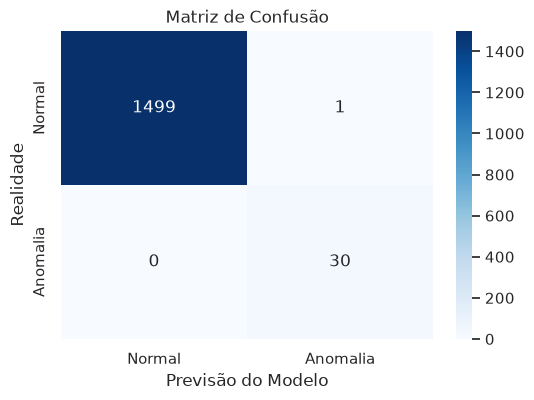

In [5]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_raw = model.predict(X_test)
y_pred = np.where(y_pred_raw == -1, 1, 0)

print("--- Relatório de Classificação ---")
print(classification_report(y_test, y_pred, target_names=['Normal', 'Anomalia']))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Anomalia'], yticklabels=['Normal', 'Anomalia'])
plt.ylabel('Realidade')
plt.xlabel('Previsão do Modelo')
plt.title('Matriz de Confusão')
plt.show()

### 5. Visualização das Transações Classificadas

Por fim, plotamos um gráfico de dispersão com os dados reais para visualizar o limite de decisão do modelo e as anomalias capturadas.

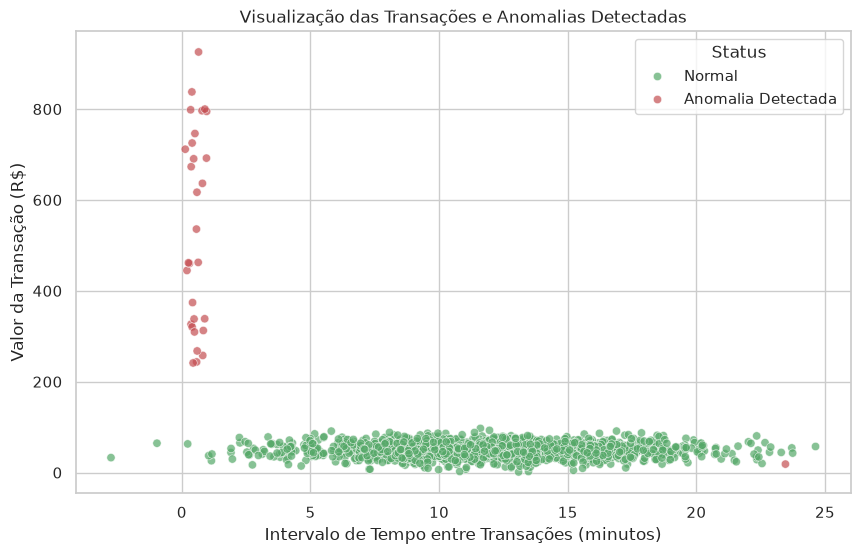

In [6]:
X_test_original = scaler.inverse_transform(X_test)
df_test = pd.DataFrame(X_test_original, columns=['Valor', 'Intervalo_Tempo'])
df_test['Previsao'] = np.where(y_pred == 1, 'Anomalia Detectada', 'Normal')

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_test,
    x='Intervalo_Tempo',
    y='Valor',
    hue='Previsao',
    palette={'Normal': 'g', 'Anomalia Detectada': 'r'},
    alpha=0.7
)

plt.title('Visualização das Transações e Anomalias Detectadas')
plt.xlabel('Intervalo de Tempo entre Transações (minutos)')
plt.ylabel('Valor da Transação (R$)')
plt.legend(title='Status')
plt.show()

## Projeto de Detecção de Fraude em Cartão de Crédito (Dados Reais)

A partir desta seção, vamos trabalhar com dados reais de transações de cartão de crédito contendo apenas 0,17% de fraudes. Vamos desenvolver um pipeline completo para tratar este severo desbalanceamento utilizando diferentes algoritmos e avaliando-os pelas métricas corretas.

### 1. Exploração dos Dados (Carregamento via URL)

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carregando o dataset real de fraudes em cartões
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df_real = pd.read_csv(url)

# Visualizando as primeiras linhas
display(df_real.head())

# Verificando o desbalanceamento das classes
print("Distribuição das Classes:")
print(df_real['Class'].value_counts())
print(f"\nProporção de fraudes: {df_real['Class'].value_counts(normalize=True)[1] * 100:.4f}%")

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Distribuição das Classes:
Class
0    284315
1       492
Name: count, dtype: int64

Proporção de fraudes: 0.1727%


### 2. Preparação e Transformação dos Dados

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Log-transform the transaction amount to reduce the impact of extreme values.
df_real['Log_Amount'] = np.log1p(df_real['Amount'])
features = [col for col in df_real.columns if col not in ['Time', 'Amount', 'Class']]
X_real = df_real[features]
y_real = df_real['Class']

# Reserve the test set first; use a separate validation set for threshold selection.
X_train_full_r, X_test_raw_r, y_train_full_r, y_test_r = train_test_split(
    X_real, y_real, test_size=0.3, random_state=42, stratify=y_real
)
X_train_raw_r, X_val_raw_r, y_train_r, y_val_r = train_test_split(
    X_train_full_r, y_train_full_r, test_size=0.2, random_state=42,
    stratify=y_train_full_r
)

# Fit preprocessing on the training subset only to avoid data leakage.
scaler_real = StandardScaler()
X_train_r = scaler_real.fit_transform(X_train_raw_r)
X_val_r = scaler_real.transform(X_val_raw_r)
X_test_r = scaler_real.transform(X_test_raw_r)

print(f'Treino: {X_train_r.shape} | Validação: {X_val_r.shape} | Teste: {X_test_r.shape}')
print(f'Fraudes - treino: {y_train_r.sum()} | validação: {y_val_r.sum()} | teste: {y_test_r.sum()}')


Treino: (159491, 29) | Validação: (39873, 29) | Teste: (85443, 29)
Fraudes - treino: 275 | validação: 69 | teste: 148


### 3. Treinamento e Comparação de Modelos (Tratando o Desbalanceamento)

Vamos treinar a Regressão Logística (Baseline), Random Forest Classifier e o XGBoost Classifier aplicando penalizações de peso de classe para lidar com as fraudes.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# 1. Regressão Logística com peso de classe balanceado
print("Treinando Regressão Logística...")
lr_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_model.fit(X_train_r, y_train_r)

# 2. Random Forest com peso de classe balanceado subamostrado
print("Treinando Random Forest (pode levar alguns segundos)...")
rf_model = RandomForestClassifier(class_weight='balanced_subsample', n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_r, y_train_r)

# 3. XGBoost com ajuste do fator de escala positivo para classe minoritária
print("Treinando XGBoost...")
scale_pos = (len(y_train_r) - y_train_r.sum()) / y_train_r.sum()
xgb_model = XGBClassifier(scale_pos_weight=scale_pos, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_r, y_train_r)

Treinando Regressão Logística...


Treinando Random Forest (pode levar alguns segundos)...


Treinando XGBoost...


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### 4. Avaliação Comparativa de Performance (Métricas de Negócio)

In [10]:
from sklearn.metrics import (
    classification_report, average_precision_score, precision_recall_curve,
    auc, precision_score, recall_score, f1_score
)

models = {
    'Regressão Logística': lr_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

for name, model in models.items():
    probs = model.predict_proba(X_test_r)[:, 1]
    preds = (probs >= 0.5).astype(int)
    precision, recall, _ = precision_recall_curve(y_test_r, probs)
    print(f"\n==================== {name} (limiar 0.5) ====================")
    print(classification_report(y_test_r, preds, target_names=['Normal', 'Fraude'], digits=4))
    print(f"PR AUC trapezoidal: {auc(recall, precision):.4f}")
    print(f"Average Precision (AP): {average_precision_score(y_test_r, probs):.4f}")



==================== Regressão Logística (limiar 0.5) ====================


              precision    recall  f1-score   support

      Normal     0.9998    0.9769    0.9882     85295
      Fraude     0.0619    0.8784    0.1157       148

    accuracy                         0.9767     85443
   macro avg     0.5308    0.9276    0.5519     85443
weighted avg     0.9982    0.9767    0.9867     85443

PR AUC trapezoidal: 0.7464
Average Precision (AP): 0.7093



==================== Random Forest (limiar 0.5) ====================


              precision    recall  f1-score   support

      Normal     0.9996    0.9998    0.9997     85295
      Fraude     0.8527    0.7432    0.7942       148

    accuracy                         0.9993     85443
   macro avg     0.9261    0.8715    0.8969     85443
weighted avg     0.9993    0.9993    0.9993     85443

PR AUC trapezoidal: 0.7719
Average Precision (AP): 0.7724



==================== XGBoost (limiar 0.5) ====================


              precision    recall  f1-score   support

      Normal     0.9996    0.9998    0.9997     85295
      Fraude     0.8864    0.7905    0.8357       148

    accuracy                         0.9995     85443
   macro avg     0.9430    0.8952    0.9177     85443
weighted avg     0.9994    0.9995    0.9994     85443

PR AUC trapezoidal: 0.8334
Average Precision (AP): 0.8335


### 5. Explicabilidade do Modelo (Importância das Variáveis)

/tmp/ipykernel_36569/2507473519.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[features[i] for i in indices[:15]], y=importances[indices[:15]], palette="viridis")


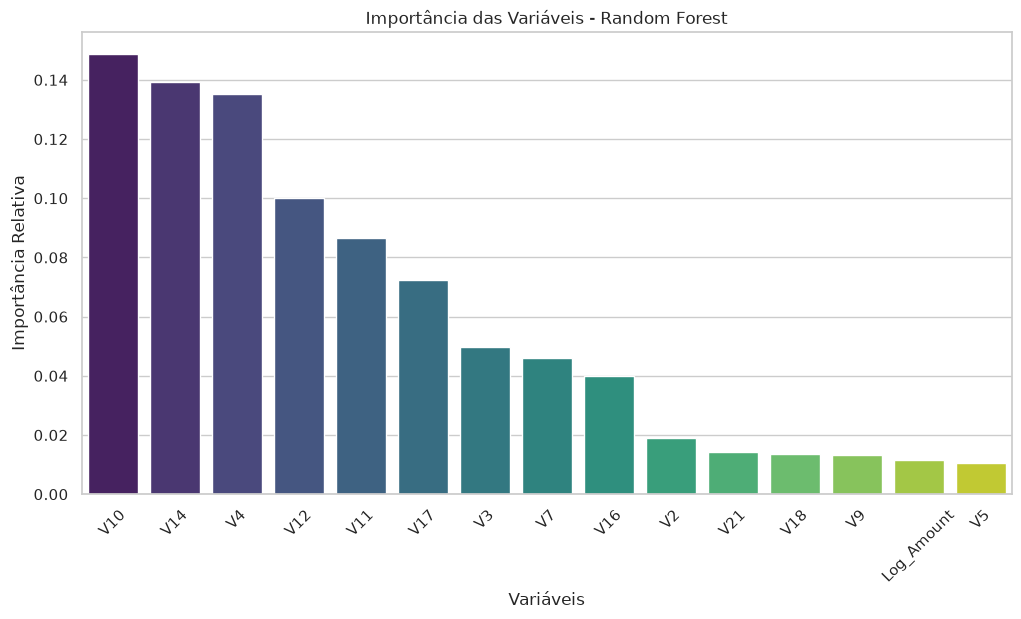

In [11]:
# Visualizando a importância de features no Random Forest para o entendimento do negócio
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 6))
plt.title("Importância das Variáveis - Random Forest")
sns.barplot(x=[features[i] for i in indices[:15]], y=importances[indices[:15]], palette="viridis")
plt.ylabel("Importância Relativa")
plt.xlabel("Variáveis")
plt.xticks(rotation=45)
plt.show()

### 6. Seleção do limiar e curva Precision-Recall

O limiar do XGBoost é escolhido maximizando o F1-score na validação. O conjunto de teste fica reservado para a avaliação final, sem participar da escolha. A curva PR compara a capacidade de ranqueamento dos três modelos; o limiar selecionado é então avaliado separadamente no teste.

Limiar selecionado (máximo F1 na validação): 0.883833
Validação - Precisão: 0.9828 | Recall: 0.8261 | F1: 0.8976



XGBoost - Padrão (0.5) - teste


              precision    recall  f1-score   support

      Normal     0.9996    0.9998    0.9997     85295
      Fraude     0.8864    0.7905    0.8357       148

    accuracy                         0.9995     85443
   macro avg     0.9430    0.8952    0.9177     85443
weighted avg     0.9994    0.9995    0.9994     85443


XGBoost - Selecionado na validação - teste


              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9997     85295
      Fraude     0.9262    0.7635    0.8370       148

    accuracy                         0.9995     85443
   macro avg     0.9629    0.8817    0.9184     85443
weighted avg     0.9995    0.9995    0.9995     85443



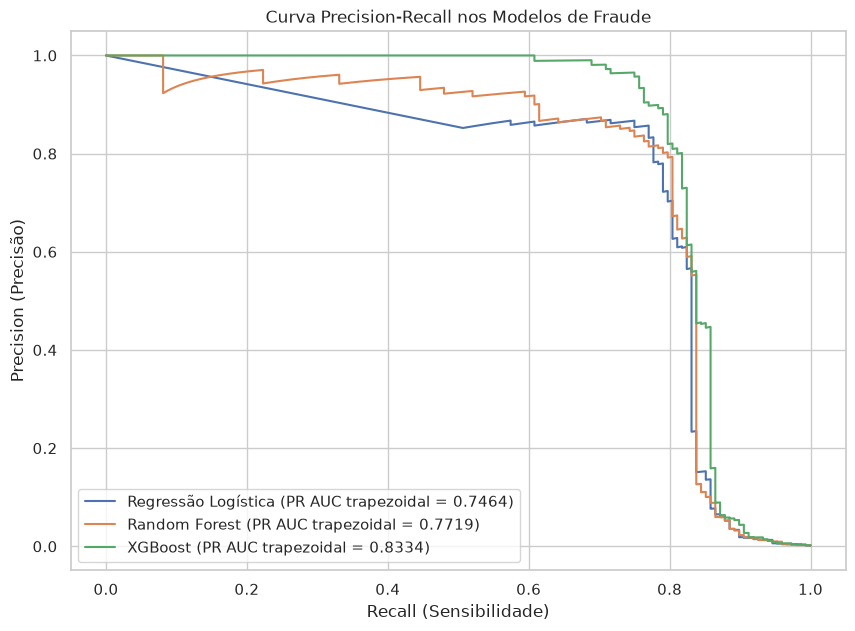

In [12]:
from sklearn.metrics import precision_recall_curve, auc

# Select the threshold using validation data only.
xgb_val_probs = xgb_model.predict_proba(X_val_r)[:, 1]
val_precision, val_recall, val_thresholds = precision_recall_curve(y_val_r, xgb_val_probs)
val_f1 = 2 * val_precision[:-1] * val_recall[:-1] / (val_precision[:-1] + val_recall[:-1] + 1e-12)
best_idx = np.argmax(val_f1)
xgb_threshold = float(val_thresholds[best_idx])
print(f'Limiar selecionado (máximo F1 na validação): {xgb_threshold:.6f}')
print(f'Validação - Precisão: {val_precision[best_idx]:.4f} | Recall: {val_recall[best_idx]:.4f} | F1: {val_f1[best_idx]:.4f}')

# Report both the default 0.5 cutoff and the validation-selected cutoff on the untouched test set.
from sklearn.metrics import classification_report
xgb_test_probs = xgb_model.predict_proba(X_test_r)[:, 1]
for label, cutoff in [('Padrão (0.5)', 0.5), ('Selecionado na validação', xgb_threshold)]:
    print(f'\nXGBoost - {label} - teste')
    xgb_test_preds = (xgb_test_probs >= cutoff).astype(int)
    print(classification_report(y_test_r, xgb_test_preds, target_names=['Normal', 'Fraude'], digits=4))

plt.figure(figsize=(10, 7))
for name, model in models.items():
    probs = model.predict_proba(X_test_r)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test_r, probs)
    pr_auc = auc(recall, precision)
    plt.plot(recall, precision, label=f'{name} (PR AUC trapezoidal = {pr_auc:.4f})')
plt.xlabel('Recall (Sensibilidade)')
plt.ylabel('Precision (Precisão)')
plt.title('Curva Precision-Recall nos Modelos de Fraude')
plt.legend(loc='best')
plt.show()


### 7. Explicabilidade com SHAP

SHAP estima a contribuição de cada variável para as previsões do Random Forest. A média do valor absoluto mostra a importância global; o gráfico beeswarm também indica direção e dispersão das contribuições.

In [13]:
!pip -q install shap

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try 'pacman -S
    python-xyz', where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Arch-packaged Python package,
    create a virtual environment using 'python -m venv path/to/venv'.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip.
    
    If you wish to install a non-Arch packaged Python application,
    it may be easiest to use 'pipx install xyz', which will manage a
    virtual environment for you. Make sure you have python-pipx
    installed via pacman.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.


/tmp/smart-fraud-venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Variável,SHAP médio absoluto
3,V4,0.070704
13,V14,0.069162
11,V12,0.066850
9,V10,0.053388
10,V11,0.047023
2,V3,0.043478
16,V17,0.023899
15,V16,0.019774
0,V1,0.014450
8,V9,0.012201


/tmp/ipykernel_36569/291211355.py:19: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(fraud_shap_values, shap_sample, max_display=15)


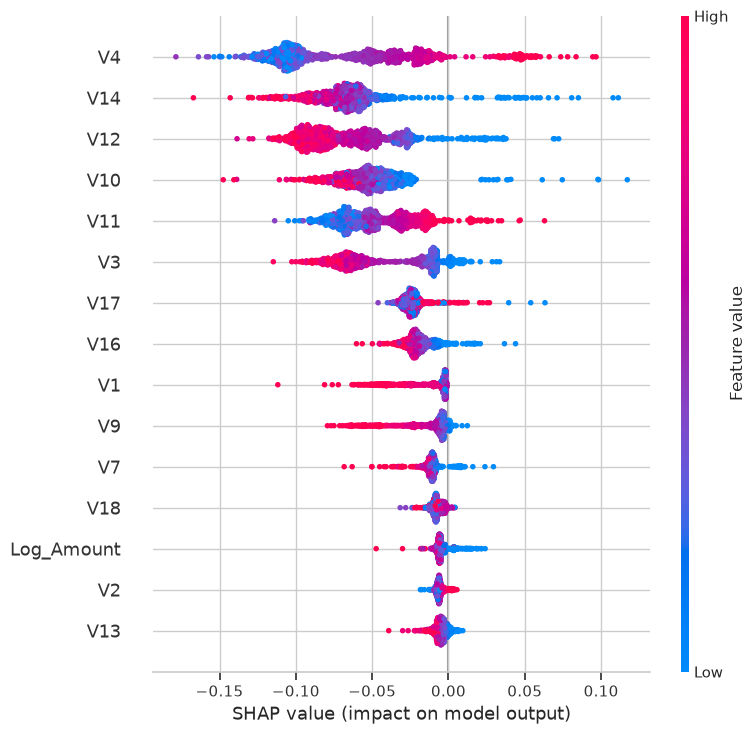

In [14]:
import shap

# Explain a reproducible sample of held-out test rows with the fraud-class SHAP values.
shap_sample = pd.DataFrame(X_test_r[:1000], columns=features)
shap_explainer = shap.TreeExplainer(rf_model)
raw_shap_values = shap_explainer.shap_values(shap_sample)
if isinstance(raw_shap_values, list):
    fraud_shap_values = raw_shap_values[1]
elif raw_shap_values.ndim == 3:
    fraud_shap_values = raw_shap_values[:, :, 1]
else:
    fraud_shap_values = raw_shap_values

shap_importance = pd.DataFrame({
    'Variável': features,
    'SHAP médio absoluto': np.abs(fraud_shap_values).mean(axis=0)
}).sort_values('SHAP médio absoluto', ascending=False)
display(shap_importance.head(10))
shap.summary_plot(fraud_shap_values, shap_sample, max_display=15)


# Detecção de Fraude em Cartões de Crédito 💳

Projeto de ciência de dados para detectar transações fraudulentas no dataset público de cartões de crédito. O [notebook executável, com células e saídas salvas](deteccao_fraude_cartao_credito.ipynb) também pode ser aberto no [Google Colab](https://colab.research.google.com/drive/1iHpy80wBIrCUQQxLJwcmsLcJ9f293aeU?usp=sharing).

## Problema e desbalanceamento

Fraudes correspondem a apenas **0,1727%** das 284.807 transações. Acurácia isolada é enganosa: prever tudo como legítimo alcançaria aproximadamente **99,83%**, mas não detectaria fraude. Por isso, a comparação prioriza precisão, recall e F1 da classe fraude; a curva Precision-Recall ajuda a avaliar modelos sem ser dominada pela classe majoritária.

## Preparação dos dados

- O CSV é carregado pelo próprio notebook de `https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv`. O dataset não está armazenado no repositório.
- `Time` é removida; `Amount` é transformada em `Log_Amount = log1p(Amount)` e a coluna original `Amount` é descartada.
- A divisão é estratificada: 30% para teste; os 70% restantes são separados em treino (80%) e validação (20%). Assim, a divisão final é 56% treino, 14% validação e 30% teste.
- O `StandardScaler` é ajustado somente no treino e aplicado à validação e ao teste, evitando vazamento de dados.

## Comparação de modelos

Os resultados abaixo são do teste, usando o limiar padrão **0,5** para todos os modelos. Regressão Logística e Random Forest usam pesos de classe; XGBoost usa `scale_pos_weight`. **PR AUC** é a área trapezoidal da curva Precision-Recall; **Average Precision (AP)** é reportada separadamente, pois usa outra agregação.

| Modelo | Precisão (fraude) | Recall (fraude) | F1 (fraude) | PR AUC trapezoidal | AP |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Regressão Logística | 0,0619 | 0,8784 | 0,1157 | 0,7464 | 0,7093 |
| Random Forest | 0,8527 | 0,7432 | 0,7942 | 0,7719 | 0,7724 |
| XGBoost | 0,8864 | 0,7905 | 0,8357 | 0,8334 | 0,8335 |

## Limiar de decisão

Para o XGBoost, selecionei o limiar que maximiza o F1 **na validação**, sem usar o teste para otimizar. O limiar encontrado foi **0,883833** (F1 de validação: 0,8976). No teste, esse limiar obteve **precisão 0,9262**, **recall 0,7635** e **F1 0,8370**. Em comparação ao limiar padrão 0,5, aumenta a precisão e reduz um pouco o recall; a escolha reflete esse compromisso e deve ser ajustada conforme o custo operacional de falsos positivos e fraudes não detectadas.

## O que SHAP mostrou

A explicação SHAP foi calculada para o **Random Forest**, em uma amostra de 1.000 transações do teste. Pela média do valor absoluto de SHAP, os quatro atributos mais influentes foram **V4 (0,0707), V14 (0,0692), V12 (0,0669) e V10 (0,0534)**, seguidos por V11. O gráfico beeswarm salvo no notebook mostra a direção e a dispersão das contribuições para a classe fraude. SHAP descreve a influência do modelo, não causalidade.

## O que foi ampliado em relação ao exercício inicial

Em relação ao exemplo inicial da Expert neste notebook (dados sintéticos e Isolation Forest), ampliei o projeto para o dataset real rotulado e acrescentei preparação de dados sem vazamento, comparação de três classificadores supervisionados com tratamento do desbalanceamento, métricas e curva Precision-Recall, seleção do limiar em validação e explicabilidade SHAP.

## Execução

Abra o notebook no Google Colab ou em Jupyter. Ele carrega os dados pela URL, treina os modelos e contém saídas salvas, relatórios de métricas e gráficos. A célula SHAP instala essa dependência quando executada.
